# M3 — Weekly bidding agent (mFRR)

General EDA is in `m3_eda_bidbook.ipynb`. This notebook only holds what the bidding study needs.

Sections
1. The task
2. The data and the split
3. How the weekly price moves
4. The bidders
5. Results on 2025
6. Final test on 2026 (empty until the end)

## 1. The task

One bidder sells **1 MW** in every **weekly** mFRR auction. It chooses one number per week: its **price**.

- bid **strictly below** the marginal price → wins and earns **its own bid**
- otherwise (equal included) → earns **0**
- goal: the highest **yearly revenue**, upwards and downwards **separately**

| Week | Bid | Marginal price | Result | Earns |
|---|---|---|---|---|
| 1 | 90 | 100 | wins | 90 |
| 2 | 100 | 100 | equal: loses | 0 |
| 3 | 70 | 80 | wins | 70 |

Earned 160 out of a best possible 280 = **57 % of best**. "Best possible" is the sum of the marginal prices: a ceiling no bid can quite reach.

**Simplification:** in reality 95 % of weekly bids strictly below the marginal price are accepted, not 100 % (see the EDA, section 4).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.data import build_auctions
from src.evaluation.revenue import score_bids, select_weekly, summarise
from src.models.bidders import (CHOOSE_YEAR, FINAL_YEAR, LAST_LEARN_YEAR,
                                DiscountBidder, ExpectedRevenueBidder, LastPriceBidder, add_last_price)
from src.models.rl_bidder import RLBidder

C1, C2, GREY, INK = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
DIR_COLOR = {"downwards": C1, "upwards": C2}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "legend.frameon": False,
})

## 2. The data and the split

One row per weekly auction and direction. The bidder may use only what was **published before its deadline**.

| Years | Role |
|---|---|
| 2019–2024 | the bidder **learns** |
| 2025 | we **compare** versions and choose settings |
| 2026 | **final test**, scored once, at the end |

A week that crosses New Year belongs to the year in Swissgrid's auction name (week of 30 Dec 2024 → `TRL_25_KW01` → 2025).

In [2]:
weekly_all = add_last_price(select_weekly(build_auctions()))
role = {**{y: "learn" for y in range(2019, LAST_LEARN_YEAR + 1)}, CHOOSE_YEAR: "compare", FINAL_YEAR: "final test"}
weeks = weekly_all.groupby(["year", "direction"]).size().unstack()
weeks.insert(0, "role", weeks.index.map(role))
display(weeks)

# the final year is put aside here: nothing below can look at its prices
weekly = weekly_all[weekly_all["year"] < FINAL_YEAR].copy()
no_last = weekly["last_price"].isna()
print(f"{no_last.sum()} auctions have no last known price (first week of each direction) and are skipped")
weekly = weekly[~no_last]

direction,role,downwards,upwards
year,,,
2019,learn,51,51
2020,learn,53,53
2021,learn,52,52
2022,learn,52,52
2023,learn,52,52
2024,learn,52,52
2025,compare,52,52
2026,final test,46,46


2 auctions have no last known price (first week of each direction) and are skipped


## 3. How the weekly price moves

`ratio` = this week's marginal price ÷ last known price. **Below 1** the price fell, so bidding the last price loses.

*Example:* last price 100, new price 95 → ratio 0.95. Bidding 100 loses; bidding 80 wins and earns 80.

Learning years only (2019–2024).

In [3]:
learn = weekly[weekly["year"] <= LAST_LEARN_YEAR].copy()
learn["ratio"] = learn["marginal"] / learn["last_price"]
rows = {}
for d, g in learn.groupby("direction"):
    rows[d] = {"weeks": f"{len(g)}",
               "price fell or stayed equal": f"{(g['ratio'] <= 1).mean():.0%}",
               "price rose": f"{(g['ratio'] > 1).mean():.0%}",
               "typical (median) change": f"{g['ratio'].median() - 1:+.1%}",
               "fell by more than 10 %": f"{(g['ratio'] < 0.9).mean():.0%}",
               "fell by more than 20 %": f"{(g['ratio'] < 0.8).mean():.0%}",
               "rose by more than 20 %": f"{(g['ratio'] > 1.2).mean():.0%}"}
pd.DataFrame(rows)

,downwards,upwards
weeks,311,311
price fell or stayed equal,65%,69%
price rose,35%,31%
typical (median) change,-6.1%,-4.3%
fell by more than 10 %,34%,20%
fell by more than 20 %,15%,4%
rose by more than 20 %,19%,12%


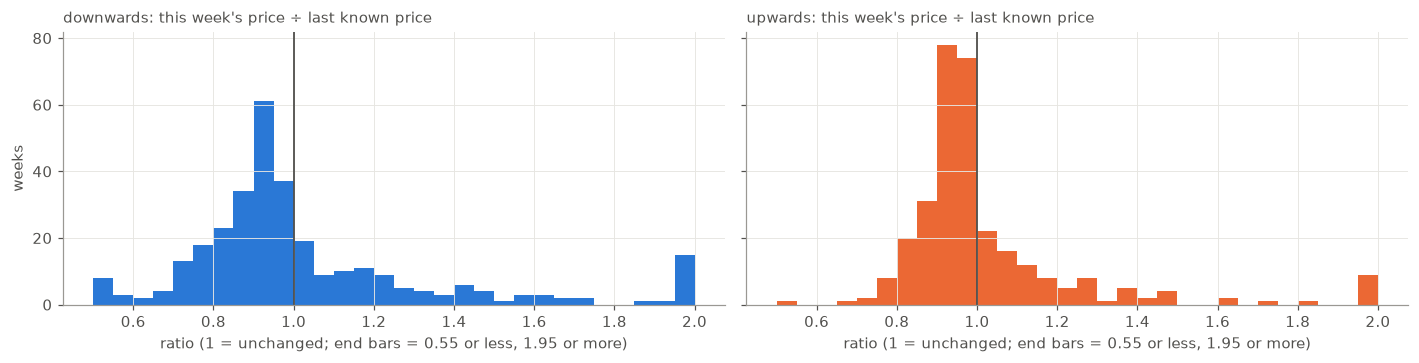

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
bins = np.arange(0.5, 2.001, 0.05)
for ax, (d, g) in zip(axes, learn.groupby("direction")):
    ax.hist(g["ratio"].clip(0.5, 1.999), bins=bins, color=DIR_COLOR[d])
    ax.axvline(1, color=INK, linewidth=1.2)
    ax.set_title(f"{d}: this week's price ÷ last known price", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("ratio (1 = unchanged; end bars = 0.55 or less, 1.95 or more)")
axes[0].set_ylabel("weeks")
fig.tight_layout()

**Takeaway:** most weeks the price slips a little, and sometimes it jumps. Bidding the last price therefore usually lands just above the new price and loses; a discount gives up a bit each week but wins almost always.

## 4. The bidders

| Bidder | Bid | Learns |
|---|---|---|
| **Last price** | the last known marginal price | nothing |
| **Discount** | factor × last known price | one factor per direction, on 2019–2024 |
| **Expected revenue** | the price with the highest *price × chance of winning* | every published week; its one setting on 2021–2024 |
| **RL (outcome)** | the factor that earned most so far | practises on 2019–2024, learns only from its own wins and losses |
| **RL (published)** | same | same, but also from what every other factor would have earned |

*Example:* last price 100, factor 0.80 → bids 80. New price 95 → wins 80. New price 75 → loses.

The factor is the one with the best **average yearly % of best**, so every year counts the same and the very expensive 2022 does not decide alone.

factor chosen on 2019-2024: {'downwards': 0.74, 'upwards': 0.8}


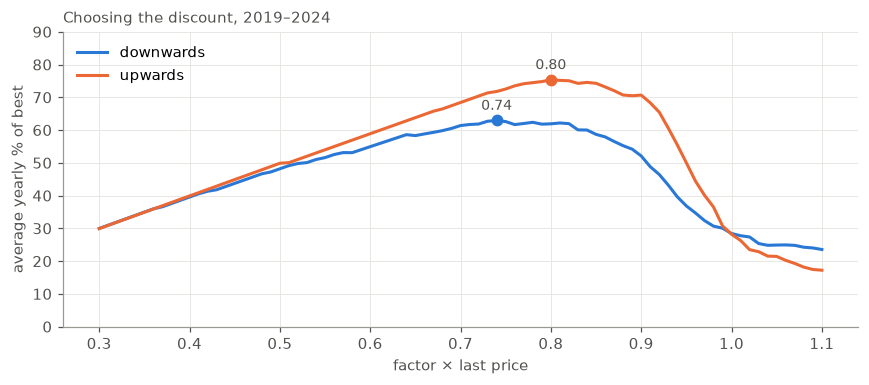

In [5]:
discount = DiscountBidder().fit(weekly)
print("factor chosen on 2019-2024:", discount.factors_)

fig, ax = plt.subplots(figsize=(8, 3.6))
for d, g in learn.groupby("direction"):
    curve = [DiscountBidder._mean_yearly_pct(g, f) for f in discount.grid]
    ax.plot(discount.grid, curve, color=DIR_COLOR[d], linewidth=2, label=d)
    best = discount.factors_[d]
    ax.scatter([best], [max(curve)], s=45, color=DIR_COLOR[d], zorder=3)
    ax.annotate(f"{best:.2f}", (best, max(curve)), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 90)
ax.set_xlabel("factor × last price"); ax.set_ylabel("average yearly % of best")
ax.set_title("Choosing the discount, 2019–2024", loc="left", fontsize=10, color=INK)
ax.legend(loc="upper left"); fig.tight_layout()

Bidding too low leaves money on the table (left side); bidding too close to the last price loses too often (the drop on the right).

**Expected-revenue bidder.** It estimates the chance of winning from past weeks, giving more weight to weeks that came after a similar price move.

*Example:* last price 100. Bidding 90 won in 5 of 10 similar weeks → worth 90 × 50 % = 45. Bidding 75 won in 9 of 10 → worth 75 × 90 % = 67.5. It bids **75**.

In [6]:
expected = ExpectedRevenueBidder().fit(weekly)     # reads only weeks published before each deadline
rl_outcome = RLBidder("outcome").fit(weekly)
rl_published = RLBidder("published").fit(weekly)
BIDDERS = {b.name: b for b in (LastPriceBidder(), discount, expected, rl_outcome, rl_published)}
FIRST_YEAR = {"expected_revenue": 2021, "rl_outcome": CHOOSE_YEAR, "rl_published": CHOOSE_YEAR}   # needs past weeks first

**RL bidder.** Each week it sees how the last price moved (fell, stable, rose), picks a factor, and remembers what that factor earned.

*Example:* after a fall it tried 0.80 three times: won, won, lost → average 0.53. It tried 0.90 three times: won, lost, lost → average 0.30. Next time after a fall it plays **0.80**.

Its bid does not change the next price, so there is nothing to plan ahead: this is the simplest form of RL (a contextual bandit). The settings were chosen by walk-forward on 2021–2024.

## 5. Results on 2025

2025 was not used to choose the factors or the setting. Revenue is in CHF for 1 MW over the year.

In [7]:
def results(year: int) -> pd.DataFrame:
    if year >= FINAL_YEAR:
        raise ValueError("the final year is scored only once, at the end (section 6)")
    due = weekly[weekly["year"] == year]
    rows = []
    for bidder in BIDDERS.values():
        t = summarise(score_bids(due, bidder.bid(due)))
        rows.append(t.assign(bidder=bidder.name))
    t = pd.concat(rows)
    return pd.DataFrame({
        "direction": t["direction"], "bidder": t["bidder"],
        "won": [f"{w} of {n}" for w, n in zip(t["wins"], t["auctions"])],
        "revenue (CHF)": t["revenue"].map("{:,.0f}".format),
        "best possible (CHF)": t["best_possible"].map("{:,.0f}".format),
        "% of best": t["pct_of_best"].map("{:.1f} %".format),
    }).sort_values("direction", kind="stable").set_index(["direction", "bidder"])

results(CHOOSE_YEAR)

won revenue (CHF) best possible (CHF)  \
direction bidder                                                         
downwards last_price        13 of 52        25,621              91,265   
          discount          47 of 52        62,021              91,265   
          expected_revenue  45 of 52        59,709              91,265   
          rl_outcome        47 of 52        61,958              91,265   
          rl_published      46 of 52        64,529              91,265   
upwards   last_price        17 of 52         4,814              14,813   
          discount          49 of 52        10,962              14,813   
          expected_revenue  45 of 52        10,720              14,813   
          rl_outcome        49 of 52        11,142              14,813   
          rl_published      49 of 52        11,255              14,813   

                           % of best  
direction bidder                      
downwards last_price          28.1 %  
          discount            68.0 %  
          expected_revenue    65.4 %  
          rl_outcome          67.9 %  
          rl_published        70.7 %  
upwards   last_price          32.5 %  
          discount            74.0 %  
          expected_revenue    72.4 %  
          rl_outcome          75.2 %  
          rl_published        76.0 %

All bidders in every year so far (% of best). The discount was chosen on 2019–2024 and the expected-revenue setting on 2021–2024, so only **2025** is a fair check. Expected revenue starts in 2021 and RL in 2025: they need past weeks to learn from.

In [8]:
def score_all(bidder) -> pd.DataFrame:
    due = weekly[weekly["year"] >= FIRST_YEAR.get(bidder.name, 2019)]
    return summarise(score_bids(due, bidder.bid(due))).assign(bidder=bidder.name)

table = pd.concat([score_all(b) for b in BIDDERS.values()])
wide = table.pivot(index="year", columns=["direction", "bidder"], values="pct_of_best")
wide = wide.reindex(columns=[(d, b) for d in ("downwards", "upwards") for b in BIDDERS])
wide.map(lambda v: "" if pd.isna(v) else f"{v:.0f} %")

direction  downwards                                                    \
bidder    last_price discount expected_revenue rl_outcome rl_published   
year                                                                     
2019            27 %     67 %                                            
2020            23 %     64 %                                            
2021            41 %     63 %             64 %                           
2022            33 %     60 %             60 %                           
2023            27 %     66 %             69 %                           
2024            20 %     57 %             56 %                           
2025            28 %     68 %             65 %       68 %         71 %   

direction    upwards                                                    
bidder    last_price discount expected_revenue rl_outcome rl_published  
year                                                                    
2019            25 %     78 %                                           
2020            29 %     68 %                                           
2021            38 %     68 %             66 %                          
2022            26 %     79 %             79 %                          
2023            30 %     81 %             83 %                          
2024            22 %     78 %             82 %                          
2025            32 %     74 %             72 %       75 %         76 %

Save the table (`results/weekly_bidders.csv`, learning and comparing years only) and the 2025 figure (`figures/m3_weekly_bidders.png`).

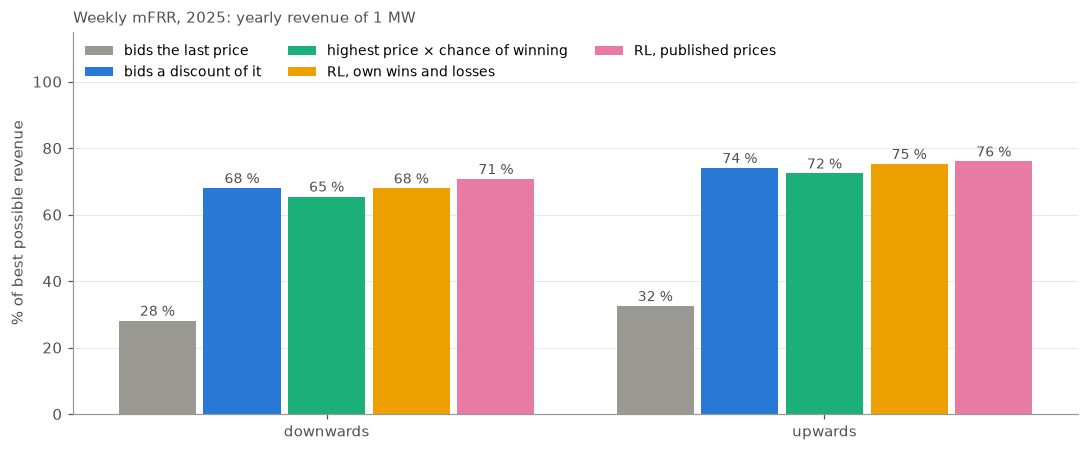

In [9]:
table["role"] = table["year"].map(role)
assert (table["year"] < FINAL_YEAR).all()          # the final year must never be in this file
table = table[["year", "role", "direction", "bidder", "auctions", "wins", "win_rate", "revenue", "best_possible", "pct_of_best"]]
table = table.sort_values(["year", "direction", "bidder"]).round({"win_rate": 4, "revenue": 2, "best_possible": 2, "pct_of_best": 2})
table.to_csv(ROOT / "results" / "weekly_bidders.csv", index=False)

chosen = table[table["year"] == CHOOSE_YEAR].pivot(index="direction", columns="bidder", values="pct_of_best")
STYLE = {"last_price": ("bids the last price", GREY), "discount": ("bids a discount of it", C1),
         "expected_revenue": ("highest price × chance of winning", "#1baf7a"),
         "rl_outcome": ("RL, own wins and losses", "#eda100"), "rl_published": ("RL, published prices", "#e87ba4")}
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (name, (label, color)) in enumerate(STYLE.items()):
    x = np.arange(len(chosen)) + (k - (len(STYLE) - 1) / 2) * 0.17
    ax.bar(x, chosen[name], width=0.155, color=color, label=label, zorder=2)
    for xi, v in zip(x, chosen[name]):
        ax.text(xi, v + 1.5, f"{v:.0f} %", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(len(chosen)), chosen.index); ax.grid(axis="x", visible=False)
ax.set_ylim(0, 115); ax.set_ylabel("% of best possible revenue")
ax.set_title(f"Weekly mFRR, {CHOOSE_YEAR}: yearly revenue of 1 MW", loc="left", fontsize=10, color=INK)
ax.legend(loc="upper left", ncol=3, fontsize=9); fig.tight_layout()
fig.savefig(ROOT / "figures" / "m3_weekly_bidders.png", bbox_inches="tight")

RL (outcome) tries bids at random while practising, so it depends on the random seed. Same agent, 20 seeds:

In [10]:
due = weekly[weekly["year"] == CHOOSE_YEAR]
runs = pd.concat([summarise(score_bids(due, RLBidder("outcome", seed=s).fit(weekly).bid(due))) for s in range(20)])
runs.groupby("direction")["pct_of_best"].agg(["mean", "min", "max"]).map("{:.1f} %".format)

,mean,min,max
direction,,,
downwards,68.0 %,61.6 %,71.3 %
upwards,75.6 %,74.0 %,80.1 %


**2025 so far**

- **RL (published)** is best: **71 % downwards, 76 % upwards**, against 68 % and 74 % for the discount.
- **RL (outcome)**, learning only from its own wins and losses, is about equal to the discount downwards (68 % on average over 20 seeds) and slightly better upwards (76 %), but depends on the seed.
- **Expected revenue** does not beat the discount (65 % and 72 %).

The gains are small (2–3 points) and come from one year of 52 weeks: upwards looks more than luck, downwards does not. Several bidders were compared on 2025, so the best one is probably a little flattered. No setting was changed after seeing 2025; **2026 decides**.

## 6. Final test on 2026

Not run yet. It is scored once, when every bidder is finished, with the settings chosen above. 2026 has 46 weeks so far, so it is compared by % of best, not by yearly CHF.